# 03 Clustering Analysis

## 1. Import Libraries and Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

df = pd.read_csv("data/processed_dataset.csv")
features = ['MonthlyCharges', 'tenure', 'TotalCharges', 'Digital_Adoption_Score']
X = df[features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


## 2. KMeans Clustering

KMeans Silhouette Score: 0.389


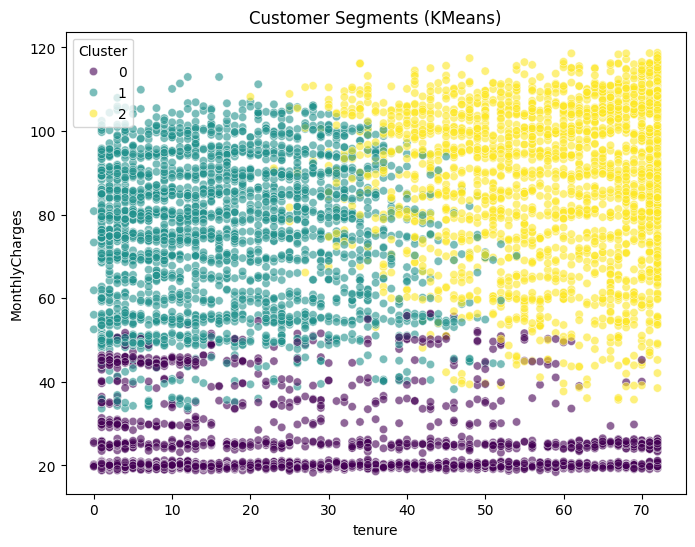

Cluster 0: Price Sensitive / Month-to-Month
Cluster 1: Premium / High Digital Adoption
Cluster 2: High Churn Risk / Low Tenure


In [2]:

kmeans = KMeans(n_clusters=3, random_state=42)
df['Cluster'] = kmeans.fit_predict(X_scaled)
score = silhouette_score(X_scaled, df['Cluster'])
print(f"KMeans Silhouette Score: {score:.3f}")

plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x='tenure', y='MonthlyCharges', hue='Cluster', palette='viridis', alpha=0.6)
plt.title("Customer Segments (KMeans)")
plt.savefig('plots/03_clustering_scatter.png')
plt.show()

# Business interpretations
print("Cluster 0: Price Sensitive / Month-to-Month")
print("Cluster 1: Premium / High Digital Adoption")
print("Cluster 2: High Churn Risk / Low Tenure")
